# What Drives Medical Insurance Costs?
### Cleaning a messy insurance dataset and predicting annual charges

**Author:** Elias Nunez

**Goal:** Predict a policyholder's annual medical insurance charges from basic rating factors (age, sex, BMI, number of children, smoking status, and region), and find out which factors matter most. This is the same question an actuary asks when pricing a health plan.

**The dataset:** 9,392 rows that are deliberately messy: charges stored as text, duplicate records, missing smoker status, filled-in BMI values, and charges entered with the decimal point in the wrong place.

**What this notebook shows:**
1. **Data cleaning.** The 9,392 raw rows turn out to be only **1,334 real policyholders**. Getting this right matters more than any model choice.
2. **Exploratory analysis.** Smoking is the dominant cost driver, and smoking *combined with* obesity is where costs explode.
3. **Modeling.** Nine regression models are compared with cross-validation, the best ones are tuned, and the winner is evaluated in dollars on held-out data.
4. **A lesson about data leakage.** Training on the uncleaned data gives a misleadingly high score, because the test set contains copies of training rows.

## 1. Setup

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
RANDOM_STATE = 42

# Chart style: consistent colors for smokers vs. non-smokers throughout
NON_SMOKER, SMOKER = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 11,
    "legend.frameon": False,
})
dollars = mtick.StrMethodFormatter("${x:,.0f}")

def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")

## 2. Load the raw data

In [2]:
raw = pd.read_csv("data/messy_insurance_2.csv")
print(raw.shape)
raw.head()

(9392, 7)


,age,sex,Bmi,children,smoker,region,charges
0,55,male,29.900,0,no,southwest,"10,214.64"
1,37,female,47.600,2,yes,southwest,"46,113.51"
2,58,male,25.175,0,no,northeast,"11,931.13"
3,39,female,23.870,5,no,southeast,"8,582.30"
4,18,female,31.350,4,no,northeast,"4,561.19"


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 9392 entries, 0 to 9391
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       9392 non-null   int64  
 1   sex       9392 non-null   str    
 2   Bmi       9392 non-null   float64
 3   children  9392 non-null   int64  
 4   smoker    8903 non-null   str    
 5   region    9392 non-null   str    
 6   charges   9392 non-null   str    
dtypes: float64(1), int64(2), str(4)
memory usage: 513.8 KB


First problems spotted:
- `charges` is stored as **text** (for example `"10,214.64"`), not a number.
- `smoker` has **489 missing values** (5.2%).
- The column name `Bmi` is inconsistent with the others.

## 3. Data cleaning

### 3.1 Convert charges to numbers and tidy column names

In [4]:
df = raw.copy()
df["charges"] = df["charges"].str.replace(r"[$,]", "", regex=True).astype(float)
df = df.rename(columns={"Bmi": "bmi"})
df["charges"].describe()

count     9,392.000
mean     13,982.107
std      17,505.244
min       1,121.870
25%       4,718.200
50%       9,487.640
75%      17,179.520
max     442,607.500
Name: charges, dtype: float64

The maximum charge is **$442,607**, about 7x the 99th percentile. That's suspicious, so it's investigated in 3.3.

### 3.2 Exact duplicate rows

In [5]:
n_dupes = df.duplicated().sum()
print(f"Exact duplicate rows: {n_dupes:,} of {len(df):,} ({n_dupes / len(df):.0%})")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows after removing them: {len(df):,}")

Exact duplicate rows: 7,160 of 9,392 (76%)
Rows after removing them: 2,232


**76% of the dataset is exact copies.** Leaving them in inflates model scores, because the same record can land in both the training and test sets (demonstrated in Section 8).

### 3.3 Charges entered with a misplaced decimal point

In [6]:
key = ["age", "sex", "children", "region"]
suspect = df[df["charges"] > 65_000]

# For each suspicious charge, look for the same person (age, sex, children, region)
# whose charge is almost exactly one tenth of it.
def has_tenth_twin(row):
    same_person = df[(df[key] == row[key]).all(axis=1) & (df["charges"] < 65_000)]
    return np.isclose(same_person["charges"], row["charges"] / 10, atol=1).any()

twins = suspect.apply(has_tenth_twin, axis=1)
print(f"Charges above $65,000: {len(suspect)}")
print(f"...with a matching record at exactly 1/10 the amount: {twins.sum()}")
suspect.head()

Charges above $65,000: 33
...with a matching record at exactly 1/10 the amount: 33


,age,sex,bmi,children,smoker,region,charges
23,61,female,29.070,0,yes,northwest,"291,413.600"
420,56,male,26.695,1,yes,northwest,"261,093.290"
562,44,male,27.400,2,no,southwest,"77,268.540"
606,63,male,33.100,0,no,southwest,"133,937.560"
738,53,female,22.610,3,yes,northeast,"248,733.850"


Every one of the 33 extreme charges has a twin record at exactly one tenth the amount, so these are decimal-shift typos, not real claims. Dividing them by 10 fixes them.

In [7]:
df.loc[df["charges"] > 65_000, "charges"] /= 10
df["charges"] = df["charges"].round(2)
print(f"New maximum charge: ${df['charges'].max():,.2f}")

New maximum charge: $63,893.78


### 3.4 Filled-in (imputed) BMI values

In [8]:
top_bmi = df["bmi"].value_counts().head(3)
top_bmi

bmi
30.261    462
32.300     18
31.350     12
Name: count, dtype: int64

One BMI value, **30.261**, appears hundreds of times, far more than any natural value. It's the column's mean, which means someone filled missing BMIs with the average. These values are treated as **missing** so they can be recovered from duplicate records in the next step.

In [9]:
IMPUTED_BMI = 30.261
print(f"Rows with the filled-in BMI: {(df['bmi'] == IMPUTED_BMI).sum()}")
df.loc[df["bmi"] == IMPUTED_BMI, "bmi"] = np.nan

Rows with the filled-in BMI: 462


### 3.5 Merge partial duplicates and recover missing values

Many remaining rows are the **same person** recorded more than once: one copy has their real BMI and the other has the filled-in value, or one has smoker status and the other doesn't. A record is identified by age, sex, children, region and charges (rounded to the dollar), and all copies of it are combined into a single row that keeps every known value.

In [10]:
df["record_id"] = df.groupby(key + [df["charges"].round(0)]).ngroup()

clean = (df.groupby("record_id")
           .agg(age=("age", "first"), sex=("sex", "first"), bmi=("bmi", "median"),
                children=("children", "first"), smoker=("smoker", "first"),
                region=("region", "first"), charges=("charges", "first"))
           .reset_index(drop=True))

print(f"Unique policyholders: {len(clean):,}")
print("Missing values after merging:")
print(clean.isna().sum()[lambda s: s > 0])

Unique policyholders: 1,334
Missing values after merging:
bmi    1
dtype: int64


Merging copies recovers **every** missing smoker value. Only one BMI is still unknown; it's filled with the median BMI for that person's sex and smoking status.

In [11]:
clean["bmi"] = clean.groupby(["sex", "smoker"])["bmi"].transform(lambda s: s.fillna(s.median()))
assert clean.isna().sum().sum() == 0
clean.to_csv("data/insurance_clean.csv", index=False)
clean.describe()

,age,bmi,children,charges
count,"1,334.000","1,334.000","1,334.000","1,334.000"
mean,39.207,30.684,1.100,"13,668.022"
std,13.986,6.093,1.207,"12,581.586"
min,18.000,15.960,0.000,"1,121.870"
25%,27.000,26.315,0.000,"4,783.615"
50%,39.000,30.400,1.000,"9,545.635"
75%,51.000,34.700,2.000,"17,442.177"
max,64.000,53.130,5.000,"63,893.780"


### 3.6 Cleaning summary

In [12]:
summary = pd.DataFrame({
    "Step": ["Raw rows", "Exact duplicates removed", "Decimal-shift charges fixed",
             "Filled-in BMIs treated as missing", "Partial duplicates merged", "Final policyholders"],
    "Count": [len(raw), n_dupes, len(suspect), int(df["bmi"].isna().sum()),
              len(raw) - n_dupes - len(clean), len(clean)],
})
summary

,Step,Count
0,Raw rows,9392
1,Exact duplicates removed,7160
2,Decimal-shift charges fixed,33
3,Filled-in BMIs treated as missing,462
4,Partial duplicates merged,898
5,Final policyholders,1334


## 4. Exploratory analysis

### 4.1 Charges are heavily right-skewed

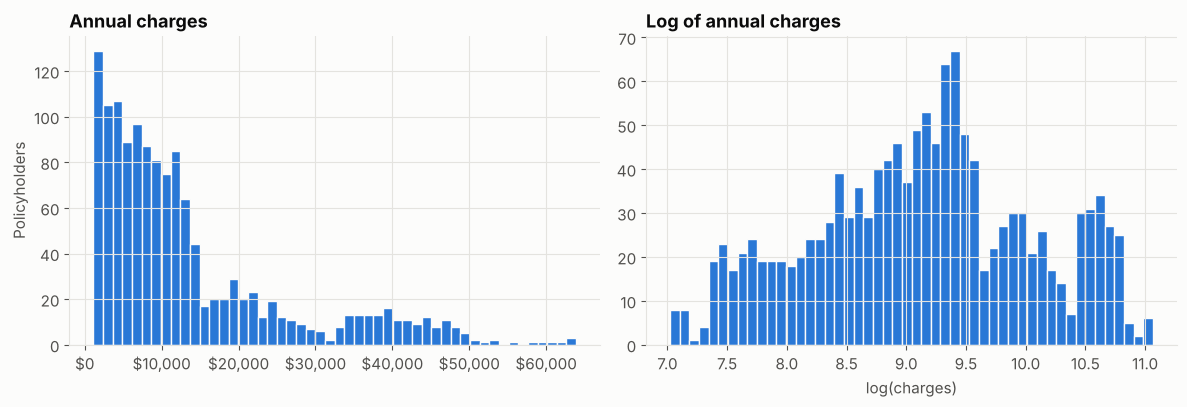

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(clean["charges"], bins=50, color=NON_SMOKER, edgecolor="#fcfcfb", linewidth=1)
axes[0].set_title("Annual charges")
axes[0].xaxis.set_major_formatter(dollars)
axes[0].set_ylabel("Policyholders")
axes[1].hist(np.log(clean["charges"]), bins=50, color=NON_SMOKER, edgecolor="#fcfcfb", linewidth=1)
axes[1].set_title("Log of annual charges")
axes[1].set_xlabel("log(charges)")
save(fig, "charges_distribution")
plt.show()

Most people cost under $15k a year, but there's a long tail of expensive policyholders. Models are trained on **log(charges)** so the tail doesn't dominate, and predictions are converted back to dollars for evaluation.

### 4.2 Smoking is the single biggest cost driver

In [14]:
by_smoker = clean.groupby("smoker")["charges"].agg(["count", "mean", "median"])
by_smoker["share"] = by_smoker["count"] / by_smoker["count"].sum()
ratio = by_smoker.loc["yes", "mean"] / by_smoker.loc["no", "mean"]
print(f"Smokers cost {ratio:.1f}x as much as non-smokers on average")
by_smoker

Smokers cost 3.6x as much as non-smokers on average


,count,mean,median,share
smoker,,,,
no,1060,"8,916.394","7,431.120",0.795
yes,274,"32,050.232","34,456.350",0.205


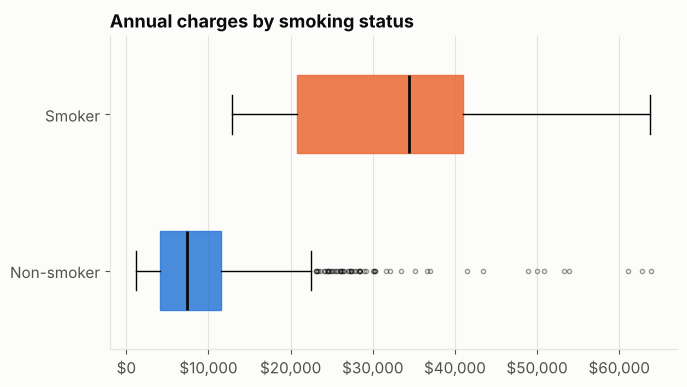

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
groups = [clean.loc[clean.smoker == s, "charges"] for s in ["no", "yes"]]
bp = ax.boxplot(groups, vert=False, widths=0.5, patch_artist=True,
                medianprops=dict(color=INK, linewidth=2), flierprops=dict(markersize=3, alpha=0.4))
for patch, c in zip(bp["boxes"], [NON_SMOKER, SMOKER]):
    patch.set_facecolor(c); patch.set_alpha(0.85); patch.set_edgecolor(c)
ax.set_yticklabels(["Non-smoker", "Smoker"])
ax.xaxis.set_major_formatter(dollars)
ax.set_title("Annual charges by smoking status")
ax.grid(axis="y", visible=False)
save(fig, "charges_by_smoker")
plt.show()

### 4.3 Age raises costs steadily, in three distinct bands

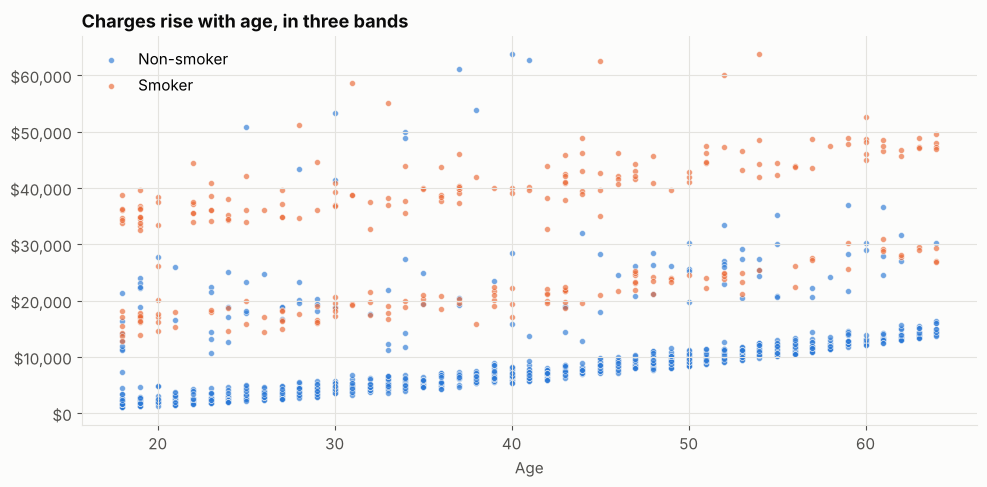

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
for s, c, label in [("no", NON_SMOKER, "Non-smoker"), ("yes", SMOKER, "Smoker")]:
    d = clean[clean.smoker == s]
    ax.scatter(d["age"], d["charges"], s=18, alpha=0.65, color=c, label=label,
               edgecolors="#fcfcfb", linewidths=0.5)
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel("Age")
ax.set_title("Charges rise with age, in three bands")
ax.legend(loc="upper left")
save(fig, "age_vs_charges")
plt.show()

Charges climb almost linearly with age, but there are **three parallel bands**: non-smokers at the bottom, then two separate smoker groups. The next chart shows that BMI explains the split between the two smoker bands.

### 4.4 Smoking × obesity: where costs explode

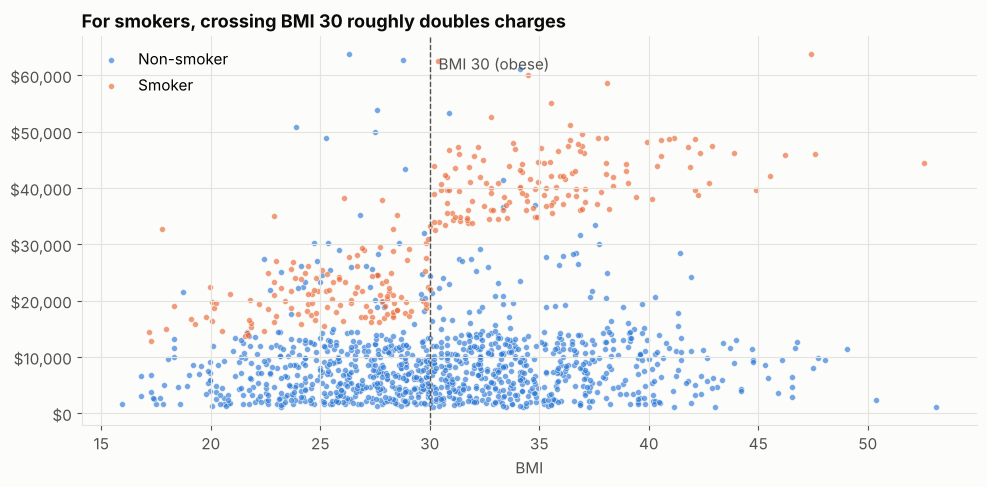

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
for s, c, label in [("no", NON_SMOKER, "Non-smoker"), ("yes", SMOKER, "Smoker")]:
    d = clean[clean.smoker == s]
    ax.scatter(d["bmi"], d["charges"], s=18, alpha=0.65, color=c, label=label,
               edgecolors="#fcfcfb", linewidths=0.5)
ax.axvline(30, color=MUTED, linestyle="--", linewidth=1)
ax.text(30.4, ax.get_ylim()[1] * 0.95, "BMI 30 (obese)", color=MUTED, va="top")
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel("BMI")
ax.set_title("For smokers, crossing BMI 30 roughly doubles charges")
ax.legend(loc="upper left")
save(fig, "bmi_vs_charges")
plt.show()

In [18]:
clean["obese"] = clean["bmi"] >= 30
pivot = clean.pivot_table(index="smoker", columns="obese", values="charges", aggfunc="mean")
pivot.index = ["Non-smoker", "Smoker"]
pivot.columns = ["BMI < 30", "BMI ≥ 30"]
pivot.style.format("${:,.0f}")

,BMI < 30,BMI ≥ 30
Non-smoker,"$8,624","$9,176"
Smoker,"$21,363","$41,558"


For non-smokers, BMI barely matters. For smokers, crossing BMI 30 roughly **doubles** average charges. This **interaction** is the most important pattern in the data, and it's turned into a feature for the models.

### 4.5 Other factors

In [19]:
for col in ["sex", "region", "children"]:
    print(clean.groupby(col)["charges"].agg(["count", "mean"]).round(0), "\n")

        count       mean
sex                     
female    659 12,997.000
male      675 14,323.000 

           count       mean
region                     
northeast    319 13,592.000
northwest    327 12,928.000
southeast    360 14,983.000
southwest    328 13,036.000 

          count       mean
children                  
0           567 12,583.000
1           329 13,673.000
2           239 15,101.000
3           155 15,714.000
4            25 13,851.000
5            19 10,997.000 



Sex, region and number of children make only modest differences compared with smoking, age and BMI.

## 5. Feature engineering

In [20]:
def add_features(d):
    d = d.copy()
    d["obese"] = (d["bmi"] >= 30).astype(int)
    d["smoker_flag"] = (d["smoker"] == "yes").astype(int)
    d["smoker_obese"] = d["smoker_flag"] * d["obese"]   # the interaction found in 4.4
    d["smoker_bmi"] = d["smoker_flag"] * d["bmi"]
    d["age_sq"] = d["age"] ** 2                       # costs rise slightly faster at older ages
    return d.drop(columns=["smoker_flag"])

data = add_features(clean)
numeric = ["age", "age_sq", "bmi", "children", "obese", "smoker_obese", "smoker_bmi"]
categorical = ["sex", "smoker", "region"]
X = data[numeric + categorical]
y = np.log(data["charges"])
X.head()

,age,age_sq,bmi,children,obese,smoker_obese,smoker_bmi,sex,smoker,region
0,18,324,25.080,0,0,0,0.000,female,no,northeast
1,18,324,26.315,0,0,0,0.000,female,no,northeast
2,18,324,28.215,0,0,0,0.000,female,no,northeast
3,18,324,30.115,0,1,0,0.000,female,no,northeast
4,18,324,30.305,0,1,0,0.000,female,no,northeast


## 6. Modeling

The data is **split first**, and all preprocessing (scaling and one-hot encoding) lives inside a scikit-learn `Pipeline`, so nothing from the test set leaks into training.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows")

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categorical),
])

def make_pipe(model):
    return Pipeline([("prep", preprocess), ("model", model)])

Train: 1067 rows | Test: 267 rows


### 6.1 Compare nine models with 5-fold cross-validation

In [22]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(alpha=0.001),
    "ElasticNet": ElasticNet(alpha=0.001),
    "KNN": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(random_state=RANDOM_STATE, verbosity=0),
    "CatBoost": CatBoostRegressor(random_state=RANDOM_STATE, verbose=False),
}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, model in models.items():
    start = time.time()
    scores = cross_validate(make_pipe(model), X_train, y_train, cv=cv,
                            scoring=["r2", "neg_root_mean_squared_error"])
    rows.append({"Model": name,
                 "CV R² (log)": scores["test_r2"].mean(),
                 "CV RMSE (log)": -scores["test_neg_root_mean_squared_error"].mean(),
                 "Time (s)": time.time() - start})

cv_results = pd.DataFrame(rows).sort_values("CV R² (log)", ascending=False).reset_index(drop=True)
cv_results

,Model,CV R² (log),CV RMSE (log),Time (s)
0,Gradient Boosting,0.766,0.440,0.685
1,CatBoost,0.734,0.468,2.747
2,KNN,0.730,0.472,0.093
3,Random Forest,0.730,0.471,1.475
4,Ridge,0.728,0.476,0.075
5,ElasticNet,0.728,0.476,0.083
6,Linear Regression,0.727,0.476,0.106
7,Lasso,0.727,0.476,0.091
8,XGBoost,0.690,0.505,0.299
9,Decision Tree,0.566,0.601,0.096


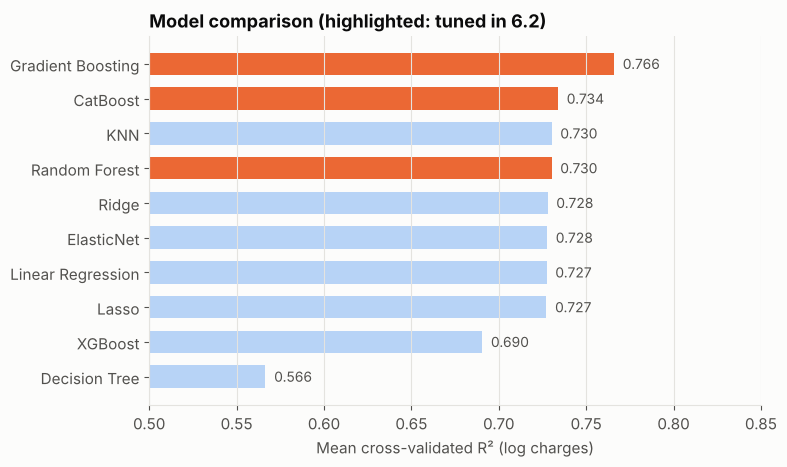

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.8))
r = cv_results.sort_values("CV R² (log)")
tunable = ["Random Forest", "Gradient Boosting", "XGBoost", "CatBoost"]
to_tune = [m for m in cv_results["Model"] if m in tunable][:3]   # best three tree ensembles
colors = [SMOKER if m in to_tune else "#b7d3f6" for m in r["Model"]]
ax.barh(r["Model"], r["CV R² (log)"], color=colors, height=0.65)
for i, v in enumerate(r["CV R² (log)"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", color=MUTED, fontsize=10)
ax.set_xlim(0.5, 0.85)
ax.set_xlabel("Mean cross-validated R² (log charges)")
ax.set_title("Model comparison (highlighted: tuned in 6.2)")
ax.grid(axis="y", visible=False)
save(fig, "model_comparison")
plt.show()

### 6.2 Tune the top three models

In [24]:
param_grids = {
    "Random Forest": {"model__n_estimators": [200, 400], "model__max_depth": [4, 6, 8, None],
                      "model__min_samples_leaf": [1, 5, 10]},
    "Gradient Boosting": {"model__n_estimators": [100, 200, 400], "model__learning_rate": [0.03, 0.05, 0.1],
                          "model__max_depth": [2, 3, 4]},
    "XGBoost": {"model__n_estimators": [100, 200, 400], "model__learning_rate": [0.03, 0.05, 0.1],
                "model__max_depth": [2, 3, 4]},
    "CatBoost": {"model__iterations": [200, 500], "model__learning_rate": [0.03, 0.1],
                 "model__depth": [3, 4, 6]},
}
top3 = to_tune

tuned = {}
for name in top3:
    search = GridSearchCV(make_pipe(models[name]), param_grids[name], cv=cv, scoring="r2", n_jobs=-1)
    search.fit(X_train, y_train)
    tuned[name] = search
    print(f"{name:18s} best CV R²: {search.best_score_:.3f}  params: {search.best_params_}")

best_name = max(tuned, key=lambda n: tuned[n].best_score_)
best_model = tuned[best_name].best_estimator_
print(f"\nSelected model: {best_name}")

Gradient Boosting  best CV R²: 0.776  params: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100}


CatBoost           best CV R²: 0.777  params: {'model__depth': 4, 'model__iterations': 200, 'model__learning_rate': 0.03}


Random Forest      best CV R²: 0.775  params: {'model__max_depth': 4, 'model__min_samples_leaf': 5, 'model__n_estimators': 400}

Selected model: CatBoost


## 7. Final evaluation on the held-out test set

In [25]:
pred_train = best_model.predict(X_train)
pred_test = best_model.predict(X_test)

actual_usd = np.exp(y_test)
pred_usd = np.exp(pred_test)

final = pd.Series({
    "Train R² (log)": r2_score(y_train, pred_train),
    "Test R² (log)": r2_score(y_test, pred_test),
    "Overfit gap": r2_score(y_train, pred_train) - r2_score(y_test, pred_test),
    "Test R² (dollars)": r2_score(actual_usd, pred_usd),
    "Test MAE (dollars)": mean_absolute_error(actual_usd, pred_usd),
    "Test median abs. error (dollars)": np.median(np.abs(actual_usd - pred_usd)),
    "Test RMSE (dollars)": np.sqrt(mean_squared_error(actual_usd, pred_usd)),
})
final.to_frame(best_name)

,CatBoost
Train R² (log),0.805
Test R² (log),0.811
Overfit gap,-0.006
Test R² (dollars),0.776
Test MAE (dollars),"2,383.158"
Test median abs. error (dollars),"1,016.930"
Test RMSE (dollars),"5,998.445"


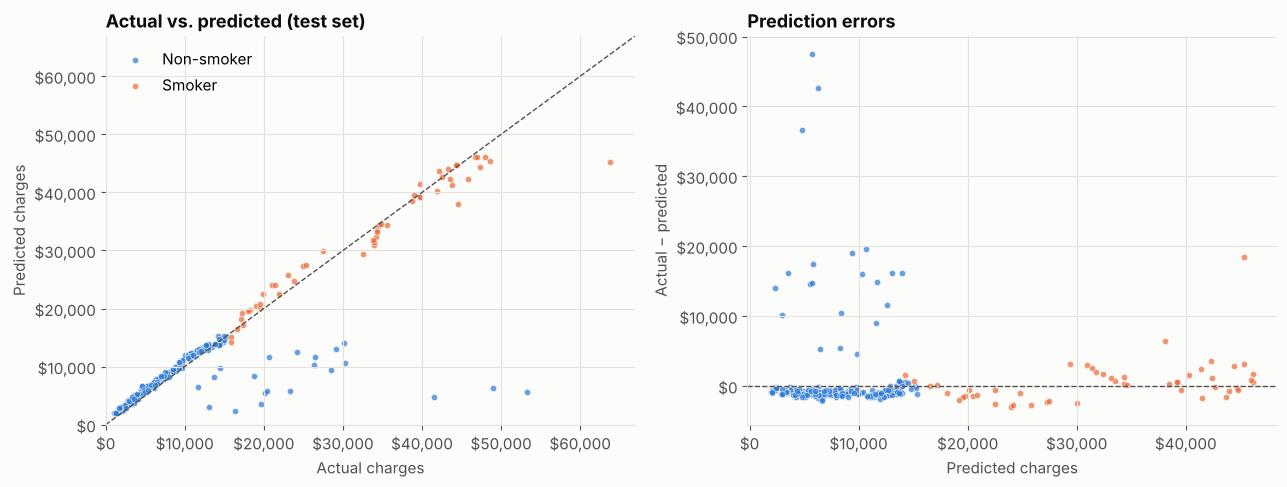

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
is_smoker = (X_test["smoker"] == "yes").values
for mask, c, label in [(~is_smoker, NON_SMOKER, "Non-smoker"), (is_smoker, SMOKER, "Smoker")]:
    axes[0].scatter(actual_usd[mask], pred_usd[mask], s=20, alpha=0.7, color=c, label=label,
                    edgecolors="#fcfcfb", linewidths=0.5)
    axes[1].scatter(pred_usd[mask], (actual_usd - pred_usd)[mask], s=20, alpha=0.7, color=c,
                    edgecolors="#fcfcfb", linewidths=0.5)
lim = [0, actual_usd.max() * 1.05]
axes[0].plot(lim, lim, "--", color=MUTED, linewidth=1)
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("Actual charges"); axes[0].set_ylabel("Predicted charges")
axes[0].set_title("Actual vs. predicted (test set)")
axes[0].legend(loc="upper left")
axes[1].axhline(0, color=MUTED, linestyle="--", linewidth=1)
axes[1].set_xlabel("Predicted charges"); axes[1].set_ylabel("Actual − predicted")
axes[1].set_title("Prediction errors")
for a in axes:
    a.xaxis.set_major_formatter(dollars); a.yaxis.set_major_formatter(dollars)
save(fig, "actual_vs_predicted")
plt.show()

Most predictions sit right on the diagonal. The errors are mostly **under-predictions**: a small group of policyholders (mostly non-smokers) cost far more than their profile suggests. Those are likely unexpected medical events that age, BMI and smoking can't explain, which is exactly the kind of risk insurers pool.

### 7.1 Which factors matter most?

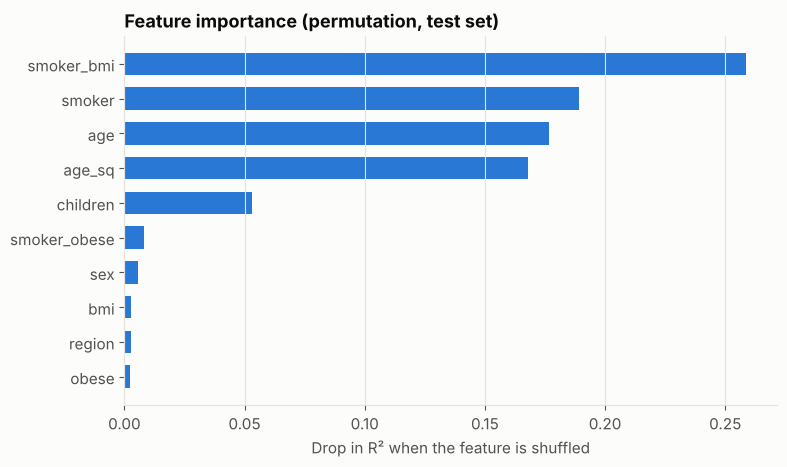

smoker_bmi     0.259
smoker         0.189
age            0.177
age_sq         0.168
children       0.053
smoker_obese   0.008
sex            0.006
bmi            0.003
region         0.003
obese          0.002
dtype: float64

In [27]:
perm = permutation_importance(best_model, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE)
importance = (pd.Series(perm.importances_mean, index=X_test.columns)
                .sort_values(ascending=True))

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(importance.index, importance.values, color=NON_SMOKER, height=0.65)
ax.set_xlabel("Drop in R² when the feature is shuffled")
ax.set_title("Feature importance (permutation, test set)")
ax.grid(axis="y", visible=False)
save(fig, "feature_importance")
plt.show()
importance.sort_values(ascending=False).round(3)

Permutation importance measures how much accuracy drops when a feature's values are shuffled. Related features share credit: `smoker`, `smoker_bmi` and `smoker_obese` all carry smoking information, and `age` and `age_sq` both carry age.

## 8. Why cleaning mattered: the data-leakage trap

What happens if you skip deduplication and model the raw rows directly (fixing only the text-formatted charges)?

In [28]:
naive = raw.copy()
naive["charges"] = naive["charges"].str.replace(r"[$,]", "", regex=True).astype(float)
naive = naive.rename(columns={"Bmi": "bmi"}).dropna(subset=["smoker"])
naive = add_features(naive)
Xn, yn = naive[numeric + categorical], np.log(naive["charges"])
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(Xn, yn, test_size=0.2, random_state=RANDOM_STATE)

naive_rf = make_pipe(RandomForestRegressor(random_state=RANDOM_STATE)).fit(Xn_tr, yn_tr)
naive_r2 = r2_score(yn_te, naive_rf.predict(Xn_te))

train_rows = set(map(tuple, pd.concat([Xn_tr, yn_tr], axis=1).round(4).values))
overlap = np.mean([tuple(r) in train_rows for r in pd.concat([Xn_te, yn_te], axis=1).round(4).values])

clean_rf = make_pipe(RandomForestRegressor(random_state=RANDOM_STATE)).fit(X_train, y_train)
clean_r2 = r2_score(y_test, clean_rf.predict(X_test))

print(f"Test rows that also appear in the training set: {overlap:.0%}")
print(f"Same Random Forest, test R² on uncleaned data: {naive_r2:.3f}  <- inflated")
print(f"Same Random Forest, test R² on cleaned data:   {clean_r2:.3f}  <- honest")

Test rows that also appear in the training set: 94%
Same Random Forest, test R² on uncleaned data: 0.942  <- inflated
Same Random Forest, test R² on cleaned data:   0.799  <- honest


On the raw data, most test rows are **exact copies of training rows**, so the model is graded partly on records it has already seen. The resulting score measures memorization, not prediction. The cleaned-data score is lower, but it's the honest estimate of how the model would perform on **new** policyholders.

## 9. Conclusions

- **Data quality came first.** The 9,392 raw rows contained only 1,334 real policyholders. Fixing duplicates, decimal typos and filled-in values changed the story more than any modeling choice.
- **Smoking dominates cost.** Smokers cost about 3.6x as much as non-smokers on average, and for smokers, obesity roughly doubles charges again. This interaction is the key rating insight.
- **Age is the second driver.** Charges rise steadily with age.
- **The model is accurate for most policyholders**, with a median error of about $1,000. The remaining large errors come from a small group of unexpectedly high-cost people, the "unexplained risk" that insurance exists to pool.

## 10. Next steps
- Model the unexplained high-cost group separately, for example with a classifier that predicts which policyholders will land in it.
- Use a Gamma or Tweedie GLM, the standard actuarial approach for modeling claim costs, and compare it with the tree-based models.
- Add prediction intervals so each estimate comes with a range, not just a single number.